# 02 — p5986 mechanical calibration and nominal-rate verification

Input: `01_mech_raw_p5986_from_binary.h5`  
Output: `02_mech_calibrated_p5986.h5`

The calibration constants and record boundaries are taken from `p5986_0_preprocessing.ipynb` and checked against the p5986 runsheet. The runsheet records one main shearing stage at **10 μm/s** under **10 MPa** normal stress. DCDT differentiation is used as an independent verification, not to invent multiple rate stages.


In [ ]:
# ===== Common setup: Google Drive path and output folder =====
from pathlib import Path
import os, json, re, math, glob, shutil, warnings
import numpy as np
import pandas as pd

try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception as exc:
    print('Not running in Colab or Drive already mounted:', exc)

# Edit only when the Drive shortcut/folder is elsewhere.
P5986_ROOT = Path(os.environ.get(
    'P5986_ROOT',
    '/content/drive/MyDrive/MLStressDrop/p5986',
))
assert P5986_ROOT.exists(), (
    f'Cannot find p5986 folder: {P5986_ROOT}. '
    'Add a Drive shortcut or edit P5986_ROOT.'
)

MECH_DIR = P5986_ROOT / 'mechData'
AC_DIR = P5986_ROOT / 'acData'
RUN1_DIR = AC_DIR / 'run1'
MAT_DIR = AC_DIR / 'MatFiles'
OUT_DIR = P5986_ROOT / 'colab_outputs_p5986'
OUT_DIR.mkdir(exist_ok=True, parents=True)
print('P5986_ROOT =', P5986_ROOT)
print('OUT_DIR    =', OUT_DIR)


Mounted at /content/drive
P5986_ROOT = /content/drive/MyDrive/MLStressDrop/p5986
OUT_DIR    = /content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986


In [ ]:
# ===== Small HDF5 utilities =====
import h5py

def _as_array(x):
    x = np.asarray(x)
    if x.dtype == object:
        x = x.astype(str)
    return x

def save_dict_h5(path, data, attrs=None):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with h5py.File(path, 'w') as f:
        for k, v in data.items():
            arr = _as_array(v)
            if arr.dtype.kind in {'U', 'O'}:
                dt = h5py.string_dtype(encoding='utf-8')
                f.create_dataset(k, data=arr.astype(str), dtype=dt)
            else:
                f.create_dataset(k, data=arr, compression='gzip', compression_opts=4, shuffle=True)
        if attrs:
            for k, v in attrs.items():
                f.attrs[k] = json.dumps(v) if isinstance(v, (dict, list, tuple)) else v
    print('saved:', path)

def load_h5_to_dict(path):
    out = {}
    with h5py.File(path, 'r') as f:
        for k in f.keys():
            out[k] = f[k][()]
            if getattr(out[k], 'dtype', None) is not None and out[k].dtype.kind == 'S':
                out[k] = out[k].astype(str)
    return out

def load_h5_to_df(path):
    d = load_h5_to_dict(path)
    return pd.DataFrame({k: np.ravel(v) for k, v in d.items() if np.asarray(v).ndim <= 1})


## 1. Input raw mechanical dataframe


In [ ]:
def load_h5_to_df(path):
    d = {}
    columns_attr = None

    with h5py.File(path, 'r') as f:
        if 'columns' in f.attrs:
            columns_attr = json.loads(f.attrs['columns'])

        for k in f.keys():
            v = f[k][()]
            if getattr(v, 'dtype', None) is not None and v.dtype.kind == 'S':
                v = v.astype(str)
            d[k] = v

    df = pd.DataFrame({k: np.ravel(v) for k, v in d.items() if np.asarray(v).ndim <= 1})

    if columns_attr is not None:
        ordered = [c for c in columns_attr if c in df.columns]
        extra = [c for c in df.columns if c not in ordered]
        df = df[ordered + extra]

    return df


In [ ]:
RAW_H5 = OUT_DIR / '01_mech_raw_p5986_from_binary.h5'
assert RAW_H5.exists(), 'Run notebook 01 first.'

data = load_h5_to_df(RAW_H5)
print(data.shape)
print(data.columns.tolist())
data.head()


(5673000, 7)
['Time', 'Vert DCDT', 'Vert LOAD', 'Hor DCDT', 'Hor LOAD', 'VOB DCDT', 'Sync']


,Time,Vert DCDT,Vert LOAD,Hor DCDT,Hor LOAD,VOB DCDT,Sync
0,10000,-8531760,-312579,-1396451,-375188,-9158700,2763755
1,10000,-8531806,-312553,-1396281,-375162,-9158700,2763761
2,10000,-8531692,-312525,-1395717,-375212,-9158700,2763771
3,10000,-8531993,-312600,-1395435,-375245,-9158700,2763769
4,10000,-8531824,-312738,-1395302,-375359,-9158700,2763772


## 2. p5986 calibration constants, geometry, and record boundaries

Constants reproduce the current p5986 preprocessing. Record markers distinguish the runsheet boundaries from the conservative steady-analysis interval.


In [ ]:
CAL = dict(
    v_load=13.0741863033492,  # mV/kN (= V/MN), vertical load cell low gain
    v_dcdt=2.845203,          # mm/V, selected vertical DCDT calibration
    vob_dcdt=1.187309,        # mm/V, selected vertical onboard DCDT calibration
    h_load=12.545,            # mV/kN (= V/MN), selected horizontal load calibration
    h_dcdt=0.670257,          # mm/V, selected horizontal DCDT calibration
    A=0.007696,               # m², 14.8 cm × 5.2 cm
    adc_bits=2**24,
    adc_range_v=20,
)

# Runsheet / original preprocessing record markers.
IDX_H_LOAD_ZERO = 10_000
IDX_V_LOAD_ZERO = 1_005_000       # vertical DCDTs inserted / zeroed
IDX_ACOUSTIC_START = 1_044_000    # runsheet p.2: <<02>>, 100 kHz, Verasonics num1
IDX_SHEAR_COMMAND = 1_054_000     # runsheet: shear @ 10 μm/s
IDX_EXP_BEG = 1_066_500           # conservative steady-analysis start
IDX_EXP_END = 4_785_700           # conservative steady-analysis end
IDX_UNLOAD = 4_957_000            # runsheet: unloaded
NOMINAL_LOADING_RATE_UM_S = 10.0

SPIKE_RANGES = [
    (1_449_086, 1_449_129),
    (3_147_540, 3_147_611),
]


In [ ]:
# Apply p5986 calibration constants and geometry
# Main source:
#   - old p5986_0_preprocessing.ipynb, cell "CALIBRATIONS USED"
#   - visually checked against p5986_runsheet.pdf
# Important:
#   load-cell constants are V/MN, equivalently mV/kN, NOT MN/V.
#   displacement constants are mm/V.


# 為了不污染原始載入的資料，複製一份獨立的 DataFrame 進行操作
df = data.copy()
for c in df.columns:
    df[c] = pd.to_numeric(df[c], errors='coerce').astype(float)

# Time: old p5986 notebook used cumulative raw Time / 10000
# Keep both recnum and calibrated time_s.
df['recnum'] = np.arange(len(df), dtype=np.int64)
df['time_s'] = np.cumsum(df['Time'].to_numpy() / 10000.0)

# 計算每個相鄰資料點的時間差 (dt)
dt = np.diff(df['time_s'].to_numpy())
med_dt = np.nanmedian(dt[dt > 0]) #大於0的dt的中位數

# 計算 Sampling Frequency, Hz = 1 / dt
df['sampfreq_hz'] = 1.0 / med_dt if np.isfinite(med_dt) and med_dt > 0 else np.nan
print('median dt =', med_dt, 's; sampling frequency ≈', df['sampfreq_hz'].iloc[0], 'Hz')

# Areas
H_Area = CAL['A']
V_Area = 2 * CAL['A']  # DDS: two shear surfaces

# Load conversions: MPa = MN / m^2; ADC conversion follows old notebook
# Load 的轉換常數：將 ADC Bits 轉換為電壓，再轉換為 MN
# 公式邏輯：1 / (感測器轉換率 * (總解析度 / 電壓範圍))
# Displacement 的轉換常數：轉換為 mm 後，再乘上 1000 轉為微米 (um)
H_Load_Cal = 1.0 / (CAL['h_load'] * (CAL['adc_bits'] / CAL['adc_range_v']))
V_Load_Cal = 1.0 / (CAL['v_load'] * (CAL['adc_bits'] / CAL['adc_range_v']))
H_Disp_Cal = CAL['h_dcdt'] * (CAL['adc_range_v'] / CAL['adc_bits']) * 1000.0
V_Disp_Cal = CAL['v_dcdt'] * (CAL['adc_range_v'] / CAL['adc_bits']) * 1000.0
VOB_Disp_Cal = CAL['vob_dcdt'] * (CAL['adc_range_v'] / CAL['adc_bits']) * 1000.0

# Raw columns -> calibrated physical columns
assert {'Hor LOAD','Vert LOAD','Hor DCDT','Vert DCDT','VOB DCDT'}.issubset(df.columns), df.columns

df['hload_mn'] = df['Hor LOAD'] * H_Load_Cal
df['hstress_mpa'] = df['hload_mn'] / H_Area
df['hdcdt_um'] = df['Hor DCDT'] * H_Disp_Cal

df['vload_mn'] = df['Vert LOAD'] * V_Load_Cal
df['vstress_mpa'] = df['vload_mn'] / V_Area
df['vdcdt_um'] = df['Vert DCDT'] * V_Disp_Cal
df['vobdcdt_um'] = -df['VOB DCDT'] * VOB_Disp_Cal

# Sync column if present
if 'Sync' in df.columns:
    df['sync'] = df['Sync']
else:
    df['sync'] = np.nan


median dt = 0.0010000000002037268 s; sampling frequency ≈ 999.9999997962732 Hz


In [ ]:
# Check
dt_raw = df['Time'].to_numpy() / 10000.0
print(pd.Series(dt_raw).value_counts().sort_index())
print('fraction of 1 ms samples =', np.mean(dt_raw == 0.001))


0.001    5672000
0.010        900
0.100         90
1.000         10
Name: count, dtype: int64
fraction of 1 ms samples = 0.9998237264234091


## 3. Zeroing、spike repair、baseline drift correction


In [ ]:
# Data Cleaning & Feature Engineering

def zero_after_index(col, idx):
    idx = int(idx)
    if 0 <= idx < len(df):
        df[col] -= df[col].iloc[idx]
        df.loc[:idx-1, col] = 0.0

# Load/DCDT zeroing
for col in ['hload_mn', 'hstress_mpa', 'hdcdt_um']:
    zero_after_index(col, IDX_H_LOAD_ZERO)
for col in ['vload_mn', 'vstress_mpa', 'vdcdt_um', 'vobdcdt_um']:
    zero_after_index(col, IDX_V_LOAD_ZERO)

# Match the old notebook: freeze the two displacement channels and Vert LOAD only.
# vstress_mpa was created earlier as an independent Shear Stress field and is not frozen.
if IDX_EXP_END < len(df):
    for col in ['vdcdt_um', 'vobdcdt_um', 'vload_mn']:
        df.loc[IDX_EXP_END:, col] = df[col].iloc[IDX_EXP_END]

# Reset displacement zero to experiment beginning.
for col in ['vdcdt_um', 'vobdcdt_um']:
    if IDX_EXP_BEG < len(df):
        df[col] -= df[col].iloc[IDX_EXP_BEG]
        df.loc[:IDX_EXP_BEG-1, col] = 0.0

# Linear spike repair on stress columns.
def remove_spike_linear(col, a, b):
    a, b = int(a), int(b)
    if a < 0 or b >= len(df) or b <= a:
        return
    j = df.columns.get_loc(col)
    df.iloc[a:b, j] = np.linspace(df.iloc[a, j], df.iloc[b, j], b-a)

for a, b in SPIKE_RANGES:
    remove_spike_linear('vstress_mpa', a, b)
    remove_spike_linear('hstress_mpa', a, b)

# Baseline drift correction used in old notebook: remove line between first and last values.
def remove_baseline(col):
    df[col] = df[col] - np.linspace(df[col].iloc[0], df[col].iloc[-1], len(df))

remove_baseline('vstress_mpa')
remove_baseline('hstress_mpa')

# Derived fields
with np.errstate(divide='ignore', invalid='ignore'):
    df['mu'] = df['vstress_mpa'] / df['hstress_mpa']
df['mu'] = df['mu'].replace([np.inf, -np.inf], np.nan).fillna(0)
df['shear_stress_mpa'] = df['vstress_mpa']
df['normal_stress_mpa'] = df['hstress_mpa']
df['load_point_displacement_um'] = df['vdcdt_um']
df['displacement_um'] = df['vobdcdt_um']

# TODO / concern:
# This cell now matches the old p5986 preprocessing field order and freeze behavior.
# However, the following assumptions must be checked:
# 1. zero indices are true stable zero-load periods, not noisy single points.
# 2. SPIKE_RANGES are instrument/data artifacts, not real stick-slip events.
# 3. remove_baseline assumes linear drift from first to last point.
# 4. vload_mn is frozen after IDX_EXP_END, while the independent vstress_mpa is not.
# 5. Compare stress before/after baseline correction before defining ML labels.


## 4. Save calibrated mechanical data


In [ ]:
# Save calibrated mechanical dataframe with MATLAB-compatible dataset names too.
CAL_H5 = OUT_DIR / '02_mech_calibrated_p5986.h5'
CAL_CSV_HEAD = OUT_DIR / '02_mech_calibrated_p5986_preview.csv'
cols_to_save = [
    'recnum','time_s','sync','sampfreq_hz',
    'hstress_mpa','hdcdt_um','vstress_mpa','vdcdt_um','vobdcdt_um',
    'normal_stress_mpa','shear_stress_mpa','load_point_displacement_um','displacement_um',
    'mu','hload_mn','vload_mn'
]
save_dict_h5(CAL_H5, {c: df[c].to_numpy() for c in cols_to_save}, attrs={'calibration': CAL, 'source_raw_h5': str(RAW_H5)})
df[cols_to_save].head(20000).to_csv(CAL_CSV_HEAD, index=False)
print('preview csv:', CAL_CSV_HEAD)


saved: /content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986/02_mech_calibrated_p5986.h5
preview csv: /content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986/02_mech_calibrated_p5986_preview.csv


In [ ]:
# Check if the file is updated
import time

print('CAL_H5:', CAL_H5)
print('exists:', CAL_H5.exists())
print('size MB:', CAL_H5.stat().st_size / 1024**2)
print('modified:', time.strftime('%Y-%m-%d %H:%M:%S', time.localtime(CAL_H5.stat().st_mtime)))


CAL_H5: /content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986/02_mech_calibrated_p5986.h5
exists: True
size MB: 310.4597063064575
modified: 2026-08-07 03:01:20


In [ ]:
# 新增
# 多存一個 experiment preview：
# 前 20000 筆很可能主要是 experiment loading 前、zeroing 前或無效段。它對檢查欄位格式有用，但對檢查 stick-slip、摩擦係數、stress drop 幾乎沒有幫助。
CAL_CSV_EXP = OUT_DIR / '02_mech_calibrated_p5986_experiment_preview.csv'

i0 = max(IDX_EXP_BEG - 5000, 0)
i1 = min(IDX_EXP_BEG + 20000, len(df))

df.loc[i0:i1, cols_to_save].to_csv(CAL_CSV_EXP, index=False)
print('experiment preview csv:', CAL_CSV_EXP)


experiment preview csv: /content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986/02_mech_calibrated_p5986_experiment_preview.csv


In [ ]:
CAL_META_JSON = OUT_DIR / '02_mech_calibrated_p5986_metadata.json'

meta = dict(
    experiment='p5986',
    source_raw_h5=str(RAW_H5),
    output_h5=str(CAL_H5),
    columns=cols_to_save,
    calibration=CAL,
    record_markers=dict(
        IDX_H_LOAD_ZERO=IDX_H_LOAD_ZERO,
        IDX_V_LOAD_ZERO=IDX_V_LOAD_ZERO,
        IDX_ACOUSTIC_START=IDX_ACOUSTIC_START,
        IDX_SHEAR_COMMAND=IDX_SHEAR_COMMAND,
        IDX_EXP_BEG=IDX_EXP_BEG,
        IDX_EXP_END=IDX_EXP_END,
        IDX_UNLOAD=IDX_UNLOAD,
    ),
    nominal_loading_rate_um_s=NOMINAL_LOADING_RATE_UM_S,
    spike_ranges=SPIKE_RANGES,
    cautions=[
        'Spike ranges are inherited from p5986_0_preprocessing and must be checked locally against raw signals.',
        'Linear baseline removal reproduces the current p5986 preprocessing and should be compared with an uncorrected sensitivity run.',
        'The nominal 10 μm/s rate comes from the runsheet; the DCDT derivative below is the independent check.',
    ],
)
CAL_META_JSON.write_text(json.dumps(meta, indent=2), encoding='utf-8')
print('metadata json:', CAL_META_JSON)


metadata json: /content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986/02_mech_calibrated_p5986_metadata.json


/tmp/ipykernel_1060/2544670002.py:10: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/events.py:89: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


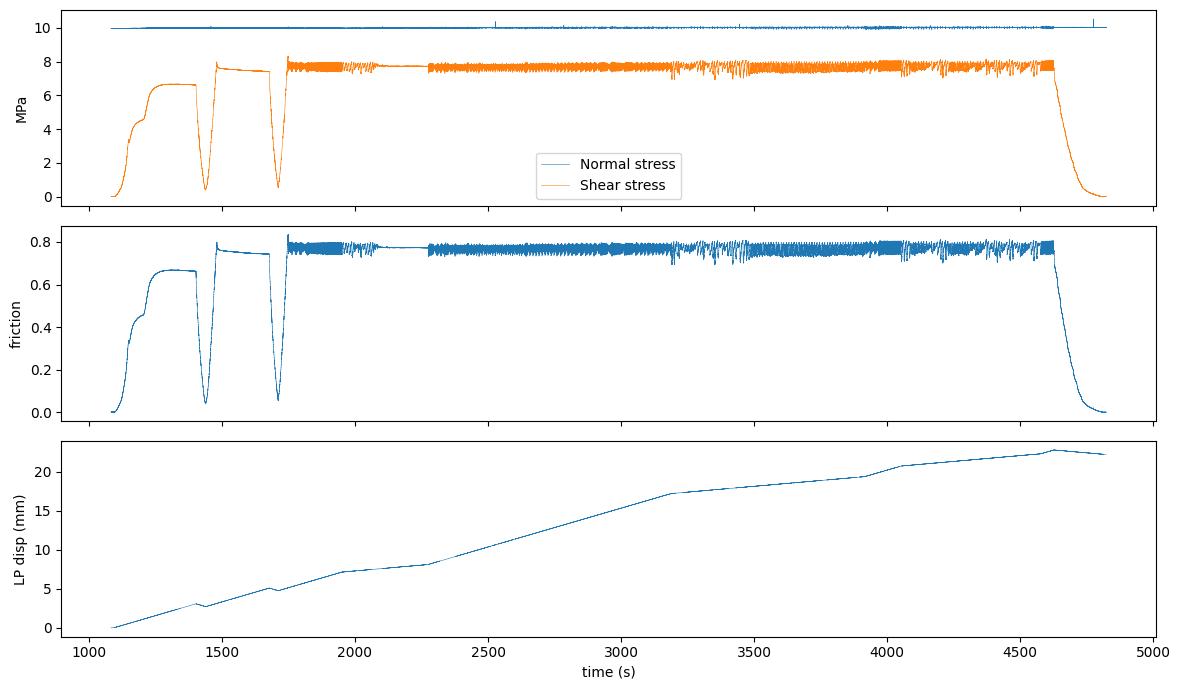

In [ ]:
# Sanity plots
import matplotlib.pyplot as plt
idx_plot = slice(max(0, IDX_EXP_BEG-10000), min(len(df), IDX_EXP_END+10000))
fig, ax = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
ax[0].plot(df['time_s'].iloc[idx_plot], df['normal_stress_mpa'].iloc[idx_plot], lw=0.4, label='Normal stress')
ax[0].plot(df['time_s'].iloc[idx_plot], df['shear_stress_mpa'].iloc[idx_plot], lw=0.4, label='Shear stress')
ax[0].legend(); ax[0].set_ylabel('MPa')
ax[1].plot(df['time_s'].iloc[idx_plot], df['mu'].iloc[idx_plot], lw=0.4); ax[1].set_ylabel('friction')
ax[2].plot(df['time_s'].iloc[idx_plot], df['load_point_displacement_um'].iloc[idx_plot]*1e-3, lw=0.4); ax[2].set_ylabel('LP disp (mm)'); ax[2].set_xlabel('time (s)')
plt.tight_layout()


In [ ]:
'''
# Verify the single nominal p5986 loading rate from load-point displacement.
from scipy import signal

LOADRATE_DISP_COL = 'load_point_displacement_um'
LR_DECIMATE_N = 10
LR_SG_WINDOW_S = 2.0
LR_SG_POLY = 3

full_time = df['time_s'].to_numpy(dtype=np.float64)
indices = np.arange(IDX_EXP_BEG, IDX_EXP_END, LR_DECIMATE_N)
td_lr = full_time[indices]
d_lr = df[LOADRATE_DISP_COL].to_numpy(dtype=np.float64)[indices]
valid = np.isfinite(td_lr) & np.isfinite(d_lr)
td_lr, d_lr = td_lr[valid], d_lr[valid]
dt_lr = float(np.nanmedian(np.diff(td_lr)))
window_rows = max(LR_SG_POLY + 2, int(round(LR_SG_WINDOW_S / dt_lr)))
if window_rows % 2 == 0:
    window_rows += 1
window_rows = min(window_rows, len(d_lr) - (1 - len(d_lr) % 2))
smooth_disp = signal.savgol_filter(d_lr, window_rows, LR_SG_POLY, mode='interp')
rate_lr = np.gradient(smooth_disp, td_lr)

df['loading_rate_um_s'] = np.interp(full_time, td_lr, rate_lr, left=np.nan, right=np.nan)
df['loading_rate_mm_s'] = df['loading_rate_um_s'] * 1e-3
df['nominal_loading_rate_um_s'] = np.nan
df.loc[IDX_EXP_BEG:IDX_EXP_END - 1, 'nominal_loading_rate_um_s'] = NOMINAL_LOADING_RATE_UM_S

steady_rate = df['loading_rate_um_s'].iloc[IDX_EXP_BEG:IDX_EXP_END].to_numpy(dtype=float)
rate_summary = {
    'nominal_um_s': NOMINAL_LOADING_RATE_UM_S,
    'measured_median_um_s': float(np.nanmedian(steady_rate)),
    'measured_mean_um_s': float(np.nanmean(steady_rate)),
    'measured_p05_um_s': float(np.nanpercentile(steady_rate, 5)),
    'measured_p95_um_s': float(np.nanpercentile(steady_rate, 95)),
}
rate_segments_df = pd.DataFrame([{
    'stage': 'run1 nominal 10 μm/s',
    'label_rate_um_s': NOMINAL_LOADING_RATE_UM_S,
    'median_rate_um_s': rate_summary['measured_median_um_s'],
    'mean_rate_um_s': rate_summary['measured_mean_um_s'],
    'p05_rate_um_s': rate_summary['measured_p05_um_s'],
    'p95_rate_um_s': rate_summary['measured_p95_um_s'],
    't_start_s': float(full_time[IDX_EXP_BEG]),
    't_end_s': float(full_time[IDX_EXP_END - 1]),
    'duration_s': float(full_time[IDX_EXP_END - 1] - full_time[IDX_EXP_BEG]),
}])
positive_levels = np.array([NOMINAL_LOADING_RATE_UM_S])

print('p5986 loading-rate verification:')
display(pd.DataFrame([rate_summary]))
display(rate_segments_df)

contain different loading rate

p5986 loading-rate verification:


,nominal_um_s,measured_median_um_s,measured_mean_um_s,measured_p05_um_s,measured_p95_um_s
0,10.0,6.921294,5.981853,-3.523641,14.498617


,stage,label_rate_um_s,median_rate_um_s,mean_rate_um_s,p05_rate_um_s,p95_rate_um_s,t_start_s,t_end_s,duration_s
0,run1 nominal 10 μm/s,10.0,6.921294,5.981853,-3.523641,14.498617,1093.501,4812.700001,3719.199001


In [ ]:
# Combined interactive HTML dashboard:
#   A. 4-panel sanity plot (including loading rate)
#   B. x-y explorer
#   C. loading-rate stage summary table
#
# Standalone HTML, no app server needed.

import json
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio

# ------------------------------------------------------------
# Helper
# ------------------------------------------------------------
def make_plot_indices_by_time(df, tmin=None, tmax=None, max_points=80000):
    t = df['time_s'].to_numpy()

    if tmin is None:
        tmin = np.nanmin(t)
    if tmax is None:
        tmax = np.nanmax(t)

    mask = np.isfinite(t) & (t >= tmin) & (t <= tmax)
    ii = np.where(mask)[0]

    if len(ii) == 0:
        raise ValueError("No data in selected time range.")

    step = max(1, int(np.ceil(len(ii) / max_points)))
    return ii[::step], step

def finite_or_none_array(x):
    x = np.asarray(x, dtype=float)
    out = []
    for v in x:
        if np.isfinite(v):
            out.append(float(v))
        else:
            out.append(None)
    return out


# ------------------------------------------------------------
# A. 4-panel sanity figure
# ------------------------------------------------------------
def make_sanity_fig(df, tmin=None, tmax=None, max_points=100000):
    ii, step = make_plot_indices_by_time(df, tmin=tmin, tmax=tmax, max_points=max_points)
    t = df['time_s'].to_numpy()[ii]

    fig = make_subplots(
        rows=4,
        cols=1,
        shared_xaxes=True,
        vertical_spacing=0.035,
        subplot_titles=[
            "Normal stress and shear stress",
            "Friction coefficient",
            "Load-point displacement",
            "Loading rate (from load-point displacement)",
        ],
    )

    # Row 1
    fig.add_trace(
        go.Scattergl(
            x=t,
            y=df['normal_stress_mpa'].to_numpy()[ii],
            mode='lines',
            name='Normal stress',
            line=dict(width=1),
        ),
        row=1, col=1
    )
    fig.add_trace(
        go.Scattergl(
            x=t,
            y=df['shear_stress_mpa'].to_numpy()[ii],
            mode='lines',
            name='Shear stress',
            line=dict(width=1),
        ),
        row=1, col=1
    )

    # Row 2
    fig.add_trace(
        go.Scattergl(
            x=t,
            y=df['mu'].to_numpy()[ii],
            mode='lines',
            name='Friction μ',
            line=dict(width=1),
        ),
        row=2, col=1
    )

    # Row 3
    fig.add_trace(
        go.Scattergl(
            x=t,
            y=df['load_point_displacement_um'].to_numpy()[ii] * 1e-3,
            mode='lines',
            name='LP displacement',
            line=dict(width=1),
        ),
        row=3, col=1
    )

    # Row 4
    fig.add_trace(
        go.Scattergl(
            x=t,
            y=df['loading_rate_um_s'].to_numpy()[ii],
            mode='lines',
            name='Loading rate',
            line=dict(width=1),
        ),
        row=4, col=1
    )

    fig.update_yaxes(title_text='MPa', row=1, col=1)
    fig.update_yaxes(title_text='friction', row=2, col=1)
    fig.update_yaxes(title_text='LP disp (mm)', row=3, col=1)
    fig.update_yaxes(title_text='load rate (um/s)', row=4, col=1)
    fig.update_xaxes(title_text='time (s)', row=4, col=1)

    fig.update_layout(
        height=950,
        title=f"A. Interactive sanity plot | shown every {step} point(s)",
        hovermode='x unified',
        legend=dict(
            x=0.01,
            y=0.99,
            bgcolor='rgba(255,255,255,0.7)',
        ),
        margin=dict(l=70, r=30, t=80, b=50),
    )

    return fig


# ------------------------------------------------------------
# Default time window
# ------------------------------------------------------------
t0 = float(df['time_s'].iloc[max(0, IDX_EXP_BEG - 10000)])
t1 = float(df['time_s'].iloc[min(len(df) - 1, IDX_EXP_END + 10000)])


# ------------------------------------------------------------
# B. Explorer data
# ------------------------------------------------------------
PLOT_COLS = [
    'time_s',
    'recnum',
    'normal_stress_mpa',
    'shear_stress_mpa',
    'hstress_mpa',
    'vstress_mpa',
    'mu',
    'load_point_displacement_um',
    'displacement_um',
    'vdcdt_um',
    'vobdcdt_um',
    'loading_rate_um_s',
    'loading_rate_mm_s',
    'nominal_loading_rate_um_s',
    'hload_mn',
    'vload_mn',
    'sync',
]
PLOT_COLS = [c for c in PLOT_COLS if c in df.columns]

ii_b, step_b = make_plot_indices_by_time(df, tmin=t0, tmax=t1, max_points=150000)

explorer_data = {}
for c in PLOT_COLS:
    explorer_data[c] = finite_or_none_array(df[c].to_numpy()[ii_b])

explorer_meta = dict(
    columns=PLOT_COLS,
    default_x='time_s',
    default_y='shear_stress_mpa' if 'shear_stress_mpa' in PLOT_COLS else PLOT_COLS[0],
    tmin=t0,
    tmax=t1,
    step=int(step_b),
)

explorer_data_json = json.dumps(explorer_data)
explorer_meta_json = json.dumps(explorer_meta)


# ------------------------------------------------------------
# C. Loading-rate segment table
# ------------------------------------------------------------
# rate_segments_df is assumed to be created by Cell 1
if 'rate_segments_df' not in globals():
    raise ValueError("rate_segments_df not found. Run the loading-rate cell first.")

rate_segments_html = rate_segments_df.to_html(index=False, classes='rate-table', border=0)

positive_levels = (
    rate_segments_df.loc[rate_segments_df['label_rate_um_s'] > 0, 'label_rate_um_s']
    .dropna()
    .unique()
)
positive_levels = np.sort(positive_levels)
positive_levels_text = ", ".join([f"{x:.1f} um/s" for x in positive_levels]) if len(positive_levels) else "(none)"


# ------------------------------------------------------------
# Build final HTML
# ------------------------------------------------------------
figA = make_sanity_fig(df, tmin=t0, tmax=t1, max_points=100000)

figA_html = pio.to_html(
    figA,
    full_html=False,
    include_plotlyjs=False,
    div_id='sanity_plot',
)

html = f"""
<!DOCTYPE html>
<html>
<head>
    <meta charset="utf-8">
    <title>p5986 Mechanical Interactive Dashboard</title>
    <script src="https://cdn.plot.ly/plotly-2.35.2.min.js"></script>
    <style>
        body {{
            font-family: Arial, sans-serif;
            margin: 24px;
            background: #fafafa;
            color: #222;
        }}
        h1, h2 {{
            margin-bottom: 8px;
        }}
        .section {{
            background: white;
            padding: 18px;
            margin-bottom: 28px;
            border-radius: 10px;
            box-shadow: 0 1px 8px rgba(0,0,0,0.08);
        }}
        .controls {{
            display: flex;
            flex-wrap: wrap;
            gap: 14px;
            align-items: center;
            margin-bottom: 12px;
        }}
        label {{
            font-weight: 600;
        }}
        select, input, button {{
            padding: 6px 8px;
            font-size: 14px;
        }}
        .note {{
            color: #555;
            font-size: 14px;
            line-height: 1.45;
        }}
        #xy_explorer {{
            width: 100%;
            height: 620px;
        }}
        table.rate-table {{
            border-collapse: collapse;
            width: 100%;
            font-size: 14px;
        }}
        table.rate-table th, table.rate-table td {{
            border: 1px solid #ddd;
            padding: 8px;
            text-align: right;
        }}
        table.rate-table th:first-child,
        table.rate-table td:first-child {{
            text-align: left;
        }}
        table.rate-table th {{
            background: #f0f0f0;
        }}
    </style>
</head>

<body>
    <h1>p5986 Mechanical Interactive Dashboard</h1>
    <p class="note">
        This HTML combines the sanity plot, x-y explorer, and loading-rate stage summary.
        Downsampling here is for visualization only and does not modify the calibrated data.
    </p>

    <div class="section">
        <h2>A. Four-panel sanity plot</h2>
        <p class="note">
            Added a loading-rate panel at the bottom. This loading rate is derived from
            load-point displacement and represents the imposed loading condition.
        </p>
        {figA_html}
    </div>

    <div class="section">
        <h2>B. Flexible x-y explorer</h2>
        <p class="note">
            Select x/y columns and time range. Then press Update Plot.
            The explorer data are shown every {step_b} point(s) to keep the HTML responsive.
        </p>

        <div class="controls">
            <label for="xSelect">x:</label>
            <select id="xSelect"></select>

            <label for="ySelect">y:</label>
            <select id="ySelect"></select>

            <label for="tMinInput">tmin:</label>
            <input id="tMinInput" type="number" step="1">

            <label for="tMaxInput">tmax:</label>
            <input id="tMaxInput" type="number" step="1">

            <button onclick="updateXYPlot()">Update Plot</button>
            <button onclick="resetTimeRange()">Reset Time</button>
        </div>

        <div id="xy_explorer"></div>
    </div>

    <div class="section">
        <h2>C. p5986 nominal-rate verification</h2>
        <p class="note">
            Runsheet nominal loading-rate levels: <b>{len(positive_levels)}</b><br>
            Levels: <b>{positive_levels_text}</b><br><br>
            This is a first-pass automatic segmentation based on smoothed load-point loading rate.
            Short high-rate stages are included, but they should be visually checked because they may represent transition/ramp periods rather than steady prescribed loading.
            Please verify the stage boundaries visually using panel A and explorer B.
        </p>
        {rate_segments_html}
    </div>

<script>
const explorerData = {explorer_data_json};
const explorerMeta = {explorer_meta_json};

function populateSelectors() {{
    const xSel = document.getElementById("xSelect");
    const ySel = document.getElementById("ySelect");

    explorerMeta.columns.forEach(col => {{
        const ox = document.createElement("option");
        ox.value = col;
        ox.text = col;
        xSel.appendChild(ox);

        const oy = document.createElement("option");
        oy.value = col;
        oy.text = col;
        ySel.appendChild(oy);
    }});

    xSel.value = explorerMeta.default_x;
    ySel.value = explorerMeta.default_y;

    document.getElementById("tMinInput").value = explorerMeta.tmin.toFixed(3);
    document.getElementById("tMaxInput").value = explorerMeta.tmax.toFixed(3);
}}

function resetTimeRange() {{
    document.getElementById("tMinInput").value = explorerMeta.tmin.toFixed(3);
    document.getElementById("tMaxInput").value = explorerMeta.tmax.toFixed(3);
    updateXYPlot();
}}

function updateXYPlot() {{
    const xCol = document.getElementById("xSelect").value;
    const yCol = document.getElementById("ySelect").value;
    const tmin = parseFloat(document.getElementById("tMinInput").value);
    const tmax = parseFloat(document.getElementById("tMaxInput").value);

    const time = explorerData["time_s"];
    const xRaw = explorerData[xCol];
    const yRaw = explorerData[yCol];

    let x = [];
    let y = [];

    for (let i = 0; i < time.length; i++) {{
        const ti = time[i];
        const xi = xRaw[i];
        const yi = yRaw[i];

        if (
            ti !== null &&
            xi !== null &&
            yi !== null &&
            ti >= tmin &&
            ti <= tmax
        ) {{
            x.push(xi);
            y.push(yi);
        }}
    }}

    const trace = {{
        x: x,
        y: y,
        type: "scattergl",
        mode: "lines",
        name: yCol + " vs " + xCol,
        line: {{width: 1}}
    }};

    const layout = {{
        title: yCol + " vs " + xCol + " | t = " + tmin.toFixed(2) + "–" + tmax.toFixed(2) + " s",
        xaxis: {{
            title: xCol,
            rangeslider: {{visible: true}}
        }},
        yaxis: {{
            title: yCol
        }},
        hovermode: "closest",
        margin: {{l: 70, r: 30, t: 70, b: 70}}
    }};

    const config = {{
        responsive: true,
        scrollZoom: true,
        displaylogo: false
    }};

    Plotly.react("xy_explorer", [trace], layout, config);
}}

populateSelectors();
updateXYPlot();
</script>

</body>
</html>
"""

DASHBOARD_HTML = OUT_DIR / '02_interactive_dashboard_p5986.html'
DASHBOARD_HTML.write_text(html, encoding='utf-8')

print("saved combined interactive dashboard:", DASHBOARD_HTML)


saved combined interactive dashboard: /content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986/02_interactive_dashboard_p5986.html
